# Exploratory Data Analysis and Data Quality

Exploratory data analysis (EDA) is the systematic first look at a dataset before any model is built. Its purpose is twofold: to understand the structure of the data – distributions, relationships, patterns over time – and to find problems – gaps, outliers, implausible values, inconsistencies. In engineering, a large share of failed data science projects can be traced back to data problems that a careful EDA would have revealed.

The statistician John Tukey, who coined the term, put it this way: EDA is detective work. We look for clues without knowing in advance what we will find. The tools are simple – summary statistics and plots – but using them well requires domain knowledge.

::: {.scenario}
**Scenario: go or no-go for a failure prediction project**

A semiconductor fab wants to predict failed production runs from its process data. A project budget for one year has been requested, and the fab manager asks you for a quick assessment before signing: "We have almost 600 sensors and more than 1,500 runs – that must be enough, right?" You have one week to look at the data.

**Your decision:** Recommend starting the project now, or first investing in better data?
:::

**Learning goals.** After this chapter you can

- describe distributions numerically (location, spread, shape) and visually (histogram, box plot),
- explore a multivariate sensor dataset with time series plots, profiles and heatmaps,
- detect outliers with the IQR rule and robust z-scores and decide how to treat them,
- characterise missing data (MCAR, MAR, MNAR) and choose an appropriate treatment,
- read a raw sensor file correctly (separator, missing value code, time stamps, time zone),
- resample and aggregate time series correctly,
- judge whether a dataset is fit for the intended analysis.

**Datasets in this chapter**

- [Appliances Energy Prediction (UCI)](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction)
- [SECOM (UCI)](https://archive.ics.uci.edu/dataset/179/secom)
- [DWD Climate Data Center – hourly station data](https://opendata.dwd.de/climate_environment/CDC/)

## Describing distributions

A single variable is described by its **location** (where are the values?), its **spread** (how much do they vary?) and its **shape** (symmetric, skewed, multimodal?).

::: {.callout-note}
## Definition: Location and spread
For observations $x_1, \dots, x_n$:

- **Mean** $\bar x = \frac{1}{n}\sum_i x_i$ and **median** (the middle value of the sorted data).
- **Sample standard deviation** $s = \sqrt{\frac{1}{n-1}\sum_i (x_i - \bar x)^2}$.
- **Quartiles** $Q_1$, $Q_3$ (25 % and 75 % quantiles) and the **interquartile range** $\text{IQR} = Q_3 - Q_1$.
- **Median absolute deviation:** with the median $\tilde x = \operatorname{median}(x_1, \dots, x_n)$,
  $$\text{MAD} = \operatorname{median}\big(|x_1 - \tilde x|, \dots, |x_n - \tilde x|\big),$$
  i.e. the median of the absolute deviations from the median.
:::

Mean and standard deviation are sensitive to extreme values: a single wrong reading of $10^6$ can dominate both. Median, IQR and MAD are **robust**: they barely change if a few values are wrong. For engineering data, where sensor glitches are common, it pays to look at both and compare them.

::: {.callout-tip}
## Which plot for which question?
- *Distribution of one variable:* histogram (shape) or box plot (compact, good for comparing groups).
- *Relationship between two variables:* scatter plot; with many points use transparency or hexbin plots.
- *Development over time:* line plot, possibly with a rolling mean.
- *Patterns over two time scales* (hour of day × weekday): heatmap.
- *Many variables at once:* correlation heatmap, pair plot of a subset.
:::

## Data quality in engineering data

Measured data pass through a long chain – sensor, signal conditioning, A/D conversion, data logger, database, export – and every link can introduce errors. Typical problems:

| Problem | Typical cause | How to detect |
| --- | --- | --- |
| Missing values | sensor dropout, logging gap, value not measured for every product | `isna()`, gaps in the time index |
| Outliers | real rare event *or* measurement error | box plot, IQR rule, robust z-score |
| Implausible values | sensor fault, wrong scaling | physical limits (e.g. humidity > 100 %) |
| Frozen values | sensor stuck, communication lost | long runs of identical values |
| Coarse resolution | A/D converter or logger rounds values (e.g. to 0.1 K) | many identical values, gaps in the histogram |
| Wrong units / time stamps | °C vs. K, local time vs. UTC | domain knowledge, comparison of sources |
| Drift and offsets | sensor ageing, recalibration | trends, steps in the time series |

::: {.callout-warning}
## Pitfall: deleting "outliers" automatically
An outlier is a value that is unusual *with respect to a model* of the data – it is not automatically an error. The rare high current peaks of a motor may be exactly the events that announce a failure. Never delete data before you understand why they are extreme, and always document what you removed.
:::

### Missing data

Almost every real dataset has gaps. How to treat them depends less on *how many* values are missing than on *why* they are missing. Statisticians distinguish three mechanisms. Because the names are notoriously confusing, we explain them with one running example.

**Example: a hardening furnace.** A thermocouple measures the furnace temperature once per minute; the target is about 850 °C. The actual temperature depends on the load: a fully loaded furnace runs hotter than a nearly empty one. The load is logged reliably by the control system. Now suppose that some temperature values are missing. Three different reasons are possible:

1. **The radio link drops messages at random.** About 10 % of the readings are lost, regardless of load, temperature or time of day. Whether a value is missing has nothing to do with the process.
2. **The logger runs in an energy-saving mode at low load.** When the furnace is nearly empty, only every fifth reading is stored. Missing values are therefore much more frequent at low load – and since low load means lower temperatures, the missing values tend to be the lower ones. But the reason for the gap (low load) is itself recorded in the data.
3. **The amplifier saturates above 900 °C.** Whenever the furnace gets too hot, the measurement fails and nothing is stored. The values are missing *because* they are high – and nothing else in the data tells us so.

::: {.callout-note}
## Definition: Missing data mechanisms
Let $R$ indicate whether a value is missing.

- **MCAR** (missing completely at random): $R$ does not depend on any variable, observed or unobserved. *Case 1 – random radio losses.*
- **MAR** (missing at random): $R$ depends only on **observed** variables. Once we know those (here: the load), the missingness tells us nothing more about the missing value. *Case 2 – energy-saving mode at low load.*
- **MNAR** (missing not at random): $R$ depends on the **missing value itself** (or on other unobserved quantities), even after accounting for everything observed. *Case 3 – saturation at high temperatures.*
:::

::: {.callout-warning}
## Pitfall: "missing at random" is not random
The name MAR is misleading: in case 2 the values are *not* missing randomly – low temperatures are missing much more often. "At random" only means "random once we take the observed variables into account". Do not read MAR as "harmless".
:::

What the mechanism means in practice:

| Mechanism | Mean of the remaining values | What helps |
| --- | --- | --- |
| MCAR | unbiased – we just have fewer values | deleting incomplete rows is acceptable; any reasonable imputation works |
| MAR | **biased** (case 2: too high, because low values are missing) | use the observed variable that explains the gaps – e.g. impute temperature from load with a regression, or average per load level |
| MNAR | **biased** (case 3: too low, because high values are missing) | the data alone cannot fix it; we need knowledge of the mechanism (e.g. "missing means > 900 °C") or a better sensor |

The live coding below simulates the furnace and shows these effects in numbers. Common strategies in practice:

- drop variables with a very high share of missing values,
- drop rows if few are affected and the mechanism is plausibly MCAR,
- impute with the median (robust) or with a model that uses the variables explaining the gaps (MAR),
- for time series: interpolate short gaps, but not long ones,
- add an indicator variable "value was missing" – missingness itself can be informative,
- above all: find out *why* the values are missing – ask the people who run the process.

In [1]:
#| code-fold: false
# Setup (as in every chapter): install packages that are not pre-installed in
# Google Colab or Anaconda, then import the standard data stack.
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:        # package not found?
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")                     # common style for all plots

## Live coding: how missing values bias a mean

We simulate the furnace from the example above: 10,000 readings, load between 0 and 1, temperature rising with load. Then we delete values according to the three mechanisms and compare the mean of the remaining values with the true mean. As a remedy for MAR we impute the missing temperatures from the load with a straight-line regression fitted on the complete rows.

In [2]:
#| code-fold: false
rng = np.random.default_rng(0)
n = 10_000
load = rng.uniform(0, 1, n)                              # observed for all readings
temp = 820 + 80 * load + rng.normal(0, 15, n)            # true temperature (°C)

missing = {
    "MCAR: random radio losses": rng.random(n) < 0.10,
    "MAR: energy-saving mode at low load": rng.random(n) < 0.8 * (1 - load),
    "MNAR: saturation above 900 °C": temp > 900,
}

rows = []
for name, m in missing.items():
    obs = ~m
    slope, intercept = np.polyfit(load[obs], temp[obs], deg=1)      # regression on complete rows
    imputed = np.where(m, intercept + slope * load, temp)
    rows.append({"mechanism": name, "share missing": m.mean(),
                 "mean of remaining": temp[obs].mean(),
                 "mean after regression imputation": imputed.mean()})
result = pd.DataFrame(rows).set_index("mechanism")
print(f"True mean temperature: {temp.mean():.1f} °C")
result.style.format({"share missing": "{:.0%}", "mean of remaining": "{:.1f}",
                     "mean after regression imputation": "{:.1f}"})

True mean temperature: 860.0 °C


,share missing,mean of remaining,mean after regression imputation
mechanism,,,
MCAR: random radio losses,10%,860.0,860.1
MAR: energy-saving mode at low load,40%,868.9,860.0
MNAR: saturation above 900 °C,8%,856.0,858.3


**Discussion.** Under MCAR, the mean of the remaining values is practically identical to the true mean. Under MAR it is too high, because the low-load (cooler) readings are under-represented – but imputing from the observed load repairs the bias almost completely, since the load explains *why* values are missing. Under MNAR the remaining mean is too low, and the regression imputation removes only part of the bias: the regression was fitted on readings below 900 °C and systematically underestimates the hot ones – it cannot know what happens above the saturation limit. A few degrees may not sound like much – but for a heat treatment with a tolerance of ±10 °C, it can decide whether a batch is released.

## Live coding: reading a raw weather file

Real measurement data rarely come as a ready-made table. In Chapter 1, the trading desk of the power plant needed temperature data to commit its output – and weather services deliver such data as raw files. As an example, we load hourly air temperature and humidity from the German Weather Service (DWD), station Trier-Petrisberg (station ID 05100). The power plant of Chapter 1 is not located in Trier, and the file contains measured values, not forecasts – but the steps are the same for any weather service and any raw sensor file.

The DWD provides the data as a zip archive containing a semicolon-separated text file plus metadata files. Missing values are coded as `-999`. This is typical for raw data: we have to know the file structure, the separator, the missing value code and the time format before we can use the data. All of this is documented in the metadata – reading it is part of CRISP-DM phase 2 (Chapter 1).

In [3]:
#| code-fold: false
from pathlib import Path
import requests

DATA = Path("data")
DATA.mkdir(exist_ok=True)               # create the folder ./data if it does not exist

def download(url, fname=None):
    """Download a file once and cache it in ./data."""
    path = DATA / (fname or url.split("/")[-1])   # default file name: last part of the URL
    if not path.exists():                         # download only if not cached yet
        r = requests.get(url, timeout=120)        # give up after 120 s without response
        r.raise_for_status()                      # stop with an error if the download failed
        path.write_bytes(r.content)
    return path

In [4]:
#| code-fold: false
import zipfile

url = ("https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
       "climate/hourly/air_temperature/recent/stundenwerte_TU_05100_akt.zip")
with zipfile.ZipFile(download(url)) as z:
    print(z.namelist())                                     # what is inside?
    name = next(n for n in z.namelist() if n.startswith("produkt"))   # the data file
    dwd = pd.read_csv(z.open(name),
                      sep=";",                  # columns are separated by semicolons
                      na_values=[-999],         # -999 is the code for "missing"
                      skipinitialspace=True)    # ignore blanks after each separator

dwd.columns = dwd.columns.str.strip()           # remove blanks around the column names
dwd.head()

['Metadaten_Stationsname_Betreibername_05100.html', 'Metadaten_Stationsname_Betreibername_05100.txt', 'Metadaten_Parameter_tu_stunde_05100.html', 'Metadaten_Parameter_tu_stunde_05100.txt', 'Metadaten_Geraete_Lufttemperatur_05100.html', 'Metadaten_Geraete_Lufttemperatur_05100.txt', 'Metadaten_Geraete_Rel_Feuchte_05100.html', 'Metadaten_Geraete_Rel_Feuchte_05100.txt', 'Metadaten_Geographie_05100.txt', 'Metadaten_Fehldaten_05100_20250411_20261012.html', 'Metadaten_Fehldaten_05100_20250411_20261012.txt', 'Metadaten_Fehlwerte_05100_20250411_20261012.txt', 'produkt_tu_stunde_20250411_20261012_05100.txt']


,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,eor
0,5100,2025041100,3,4.9,83.0,eor
1,5100,2025041101,3,4.5,85.0,eor
2,5100,2025041102,3,3.6,88.0,eor
3,5100,2025041103,3,2.8,91.0,eor
4,5100,2025041104,3,1.8,92.0,eor


The raw table has cryptic column names (`TT_TU` = air temperature in °C, `RF_TU` = relative humidity in %, `QN_9` = quality level). `STATIONS_ID` and `QN_9` are stored as numbers but are codes, i.e. categorical variables (Chapter 1). The time stamp `MESS_DATUM` is an integer such as `2025041113` (year, month, day, hour). We convert the time stamp into a proper `datetime`, use it as the index and give the columns meaningful names:

In [5]:
#| code-fold: false
# MESS_DATUM is an integer such as 2025041113 (year, month, day, hour):
# convert it to text and parse it with the matching format into a real time stamp.
dwd["time"] = pd.to_datetime(dwd["MESS_DATUM"].astype(str), format="%Y%m%d%H")
weather = (dwd.set_index("time")[["TT_TU", "RF_TU"]]           # time as index, two columns
              .rename(columns={"TT_TU": "temp_C", "RF_TU": "rel_humidity_pct"}))
print(weather.isna().sum())     # number of missing values per column
weather.tail()                  # last five rows

temp_C              19
rel_humidity_pct    19
dtype: int64


,temp_C,rel_humidity_pct
time,,
2026-10-12 19:00:00,12.3,71.0
2026-10-12 20:00:00,11.4,74.0
2026-10-12 21:00:00,10.9,76.0
2026-10-12 22:00:00,9.9,82.0
2026-10-12 23:00:00,9.8,78.0


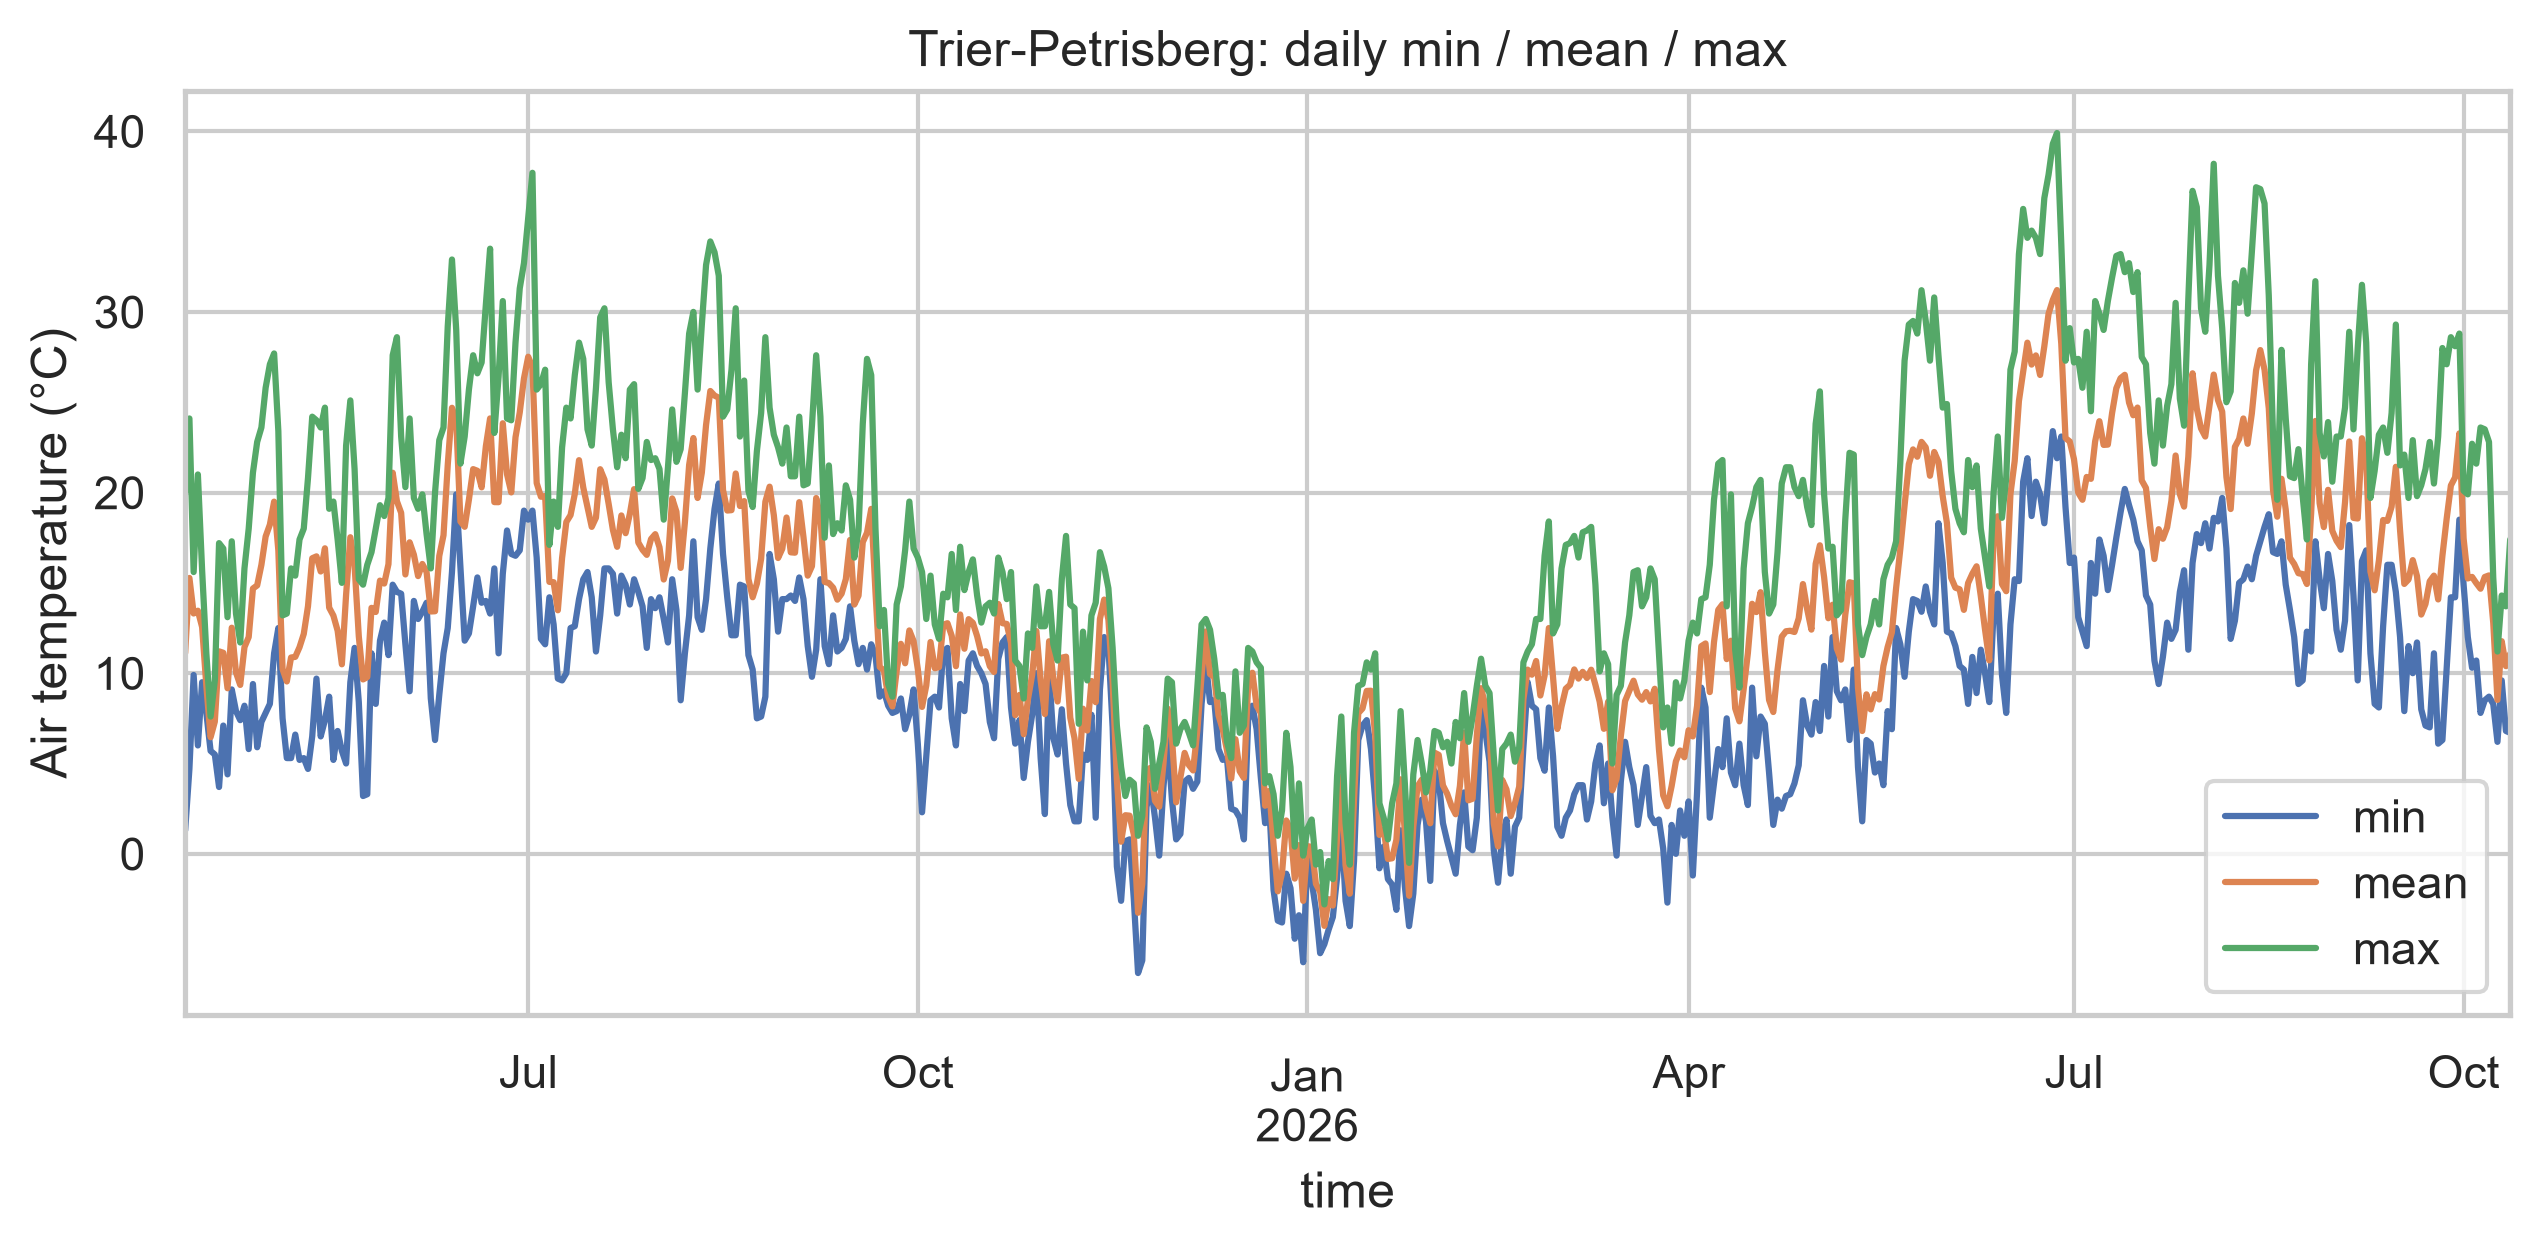

In [6]:
# resample("D") groups the hourly values by day; agg computes three statistics per day.
ax = weather["temp_C"].resample("D").agg(["min", "mean", "max"]).plot(figsize=(10, 4))
ax.set(ylabel="Air temperature (°C)", title="Trier-Petrisberg: daily min / mean / max")
plt.show()

**Discussion.** With a time index, pandas offers powerful operations: `resample("D")` aggregates hourly values to days, and we can compute several statistics at once. The plot shows the seasonal cycle and the day-to-day weather variability. Note the time zone: the DWD files of this product use UTC. When you combine such data with local production data, time zones and daylight saving time must be handled explicitly – a common source of one-hour shifts.

The output above also reports a few missing hours – the former `-999` codes, now `NaN`. Why they are missing is documented in the metadata file `Metadaten_Fehldaten_…` in the archive. Reading it is the first step before choosing a treatment (see *Missing data* above).

::: {.callout-tip}
## Engineering practice: data from databases
In companies, engineering data often come from databases rather than files – process data from a historian, quality and order data from a manufacturing execution system. They are read with SQL: a few commands such as `SELECT`, `WHERE`, `GROUP BY` and `JOIN` cover most needs, and `pd.read_sql` loads the result directly into pandas. The questions of this section remain the same: units, missing values (in SQL: `NULL`) and time zones. @sec-databases gives a short introduction.
:::

## Live coding: energy use of a low-energy house

The dataset was recorded in a low-energy house in Belgium. A wireless sensor network measured temperature and humidity in nine rooms every 10 minutes for about 4.5 months; the electricity consumption of the appliances was logged by an energy meter, and outdoor weather was taken from a nearby airport. Key columns:

| Column | Meaning | Unit |
| --- | --- | --- |
| `Appliances` | energy use of appliances in the 10-minute interval | Wh |
| `lights` | energy use of light fixtures | Wh |
| `T1` … `T9`, `RH_1` … `RH_9` | temperature and relative humidity in the rooms | °C, % |
| `T_out`, `RH_out`, `Windspeed`, … | outdoor weather | various |
| `rv1`, `rv2` | random variables, added deliberately by the authors | – |

The two random variables are a nice feature of this dataset: a sound analysis should find that they carry no information.

In [7]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

appl = fetch_ucirepo(id=374)
energy = appl.data.original.copy()

# Time stamps come in many formats. Look at the raw strings first ...
raw = energy["date"].astype(str).str.strip()
print("Raw time stamps:", raw.iloc[:3].tolist())

# ... and parse them with an explicit format instead of letting pandas guess.
def parse_timestamps(s, formats=("%Y-%m-%d %H:%M:%S", "%Y-%m-%d%H:%M:%S", "%Y-%m-%d %H:%M", "%d-%m-%Y %H:%M:%S",
                                 "%d-%m-%Y %H:%M", "%d/%m/%Y %H:%M", "%m/%d/%Y %H:%M",
                                 "%d.%m.%Y %H:%M")):
    for fmt in formats:
        t = pd.to_datetime(s, format=fmt, errors="coerce")
        if t.notna().all():
            print("Time stamp format:", fmt)
            return t
    bad = s[pd.to_datetime(s, format="mixed", errors="coerce").isna()]
    raise ValueError(f"Unknown time stamp format, e.g. {bad.iloc[:3].tolist() or s.iloc[:3].tolist()}")

energy["date"] = parse_timestamps(raw)
energy = energy.set_index("date").sort_index()
print(energy.shape, energy.index.min(), "to", energy.index.max())
print("Missing values:", energy.isna().sum().sum())
print("Regular 10-min grid:", (energy.index.to_series().diff().dropna() == pd.Timedelta("10min")).all())

Raw time stamps: ['2016-01-1117:00:00', '2016-01-1117:10:00', '2016-01-1117:20:00']
Time stamp format: %Y-%m-%d%H:%M:%S
(19735, 28) 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Missing values: 0
Regular 10-min grid: True


::: {.callout-warning}
## Pitfall: letting the software guess date formats
Is `03/04/2016` the 3rd of April or the 4th of March? If you let pandas guess, it may parse some time stamps one way and others the other way – or fail on a single unusual entry. Always look at the raw strings and give the format explicitly. Because the measurement period contains days after the 12th, only the correct order of day and month can parse *all* time stamps – the helper above uses exactly this check.
:::

A real-world surprise: in the version of this dataset served by the UCI repository, date and time are glued together without a space (`2016-01-1117:00:00` for 11 January 2016, 17:00). pandas cannot guess this format – but the explicit format `%Y-%m-%d%H:%M:%S` reads it without problems.

Checking that the time index is regular is a quick but important test. Gaps in the time grid are "hidden" missing values: `isna()` does not see them because the rows do not exist at all.

### The target variable: appliance energy use

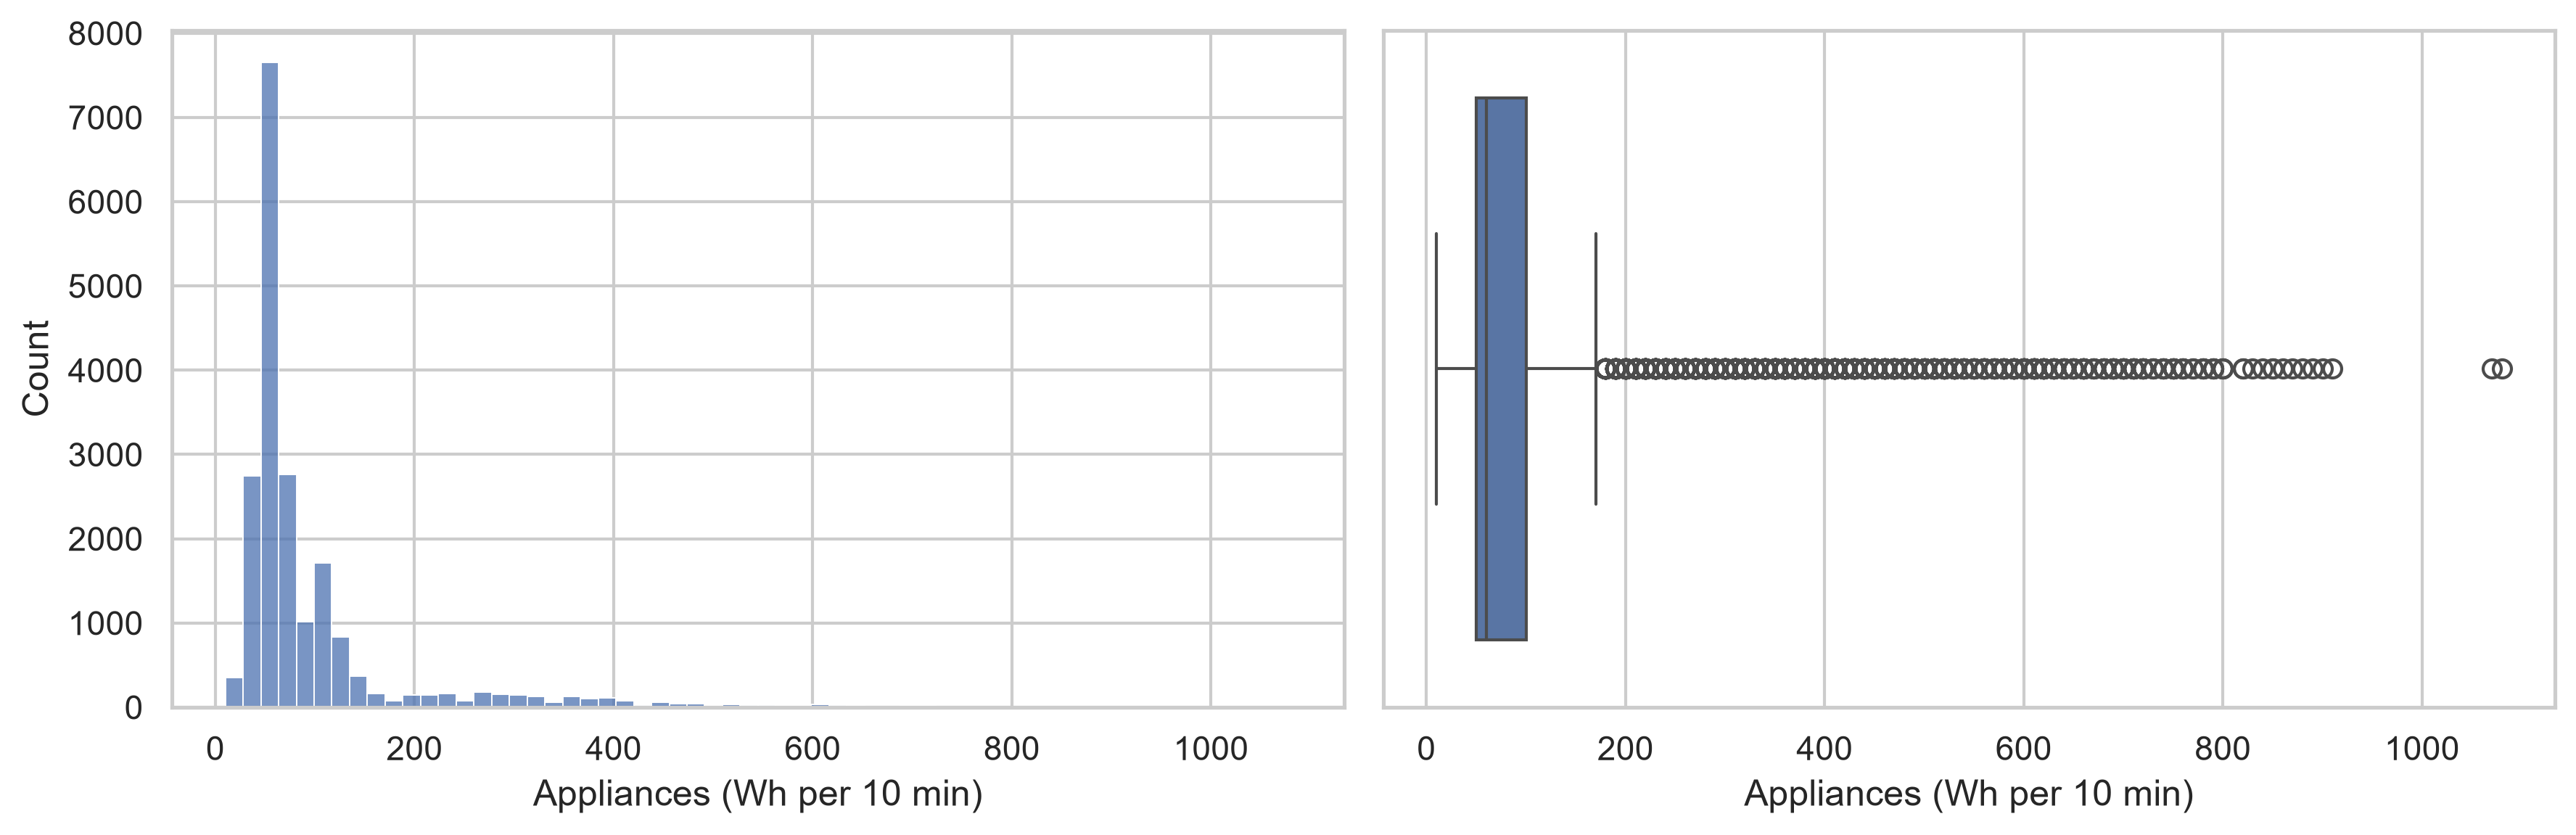

count    19735.0
mean        97.7
std        102.5
min         10.0
25%         50.0
50%         60.0
75%        100.0
max       1080.0
Name: Appliances, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(energy["Appliances"], bins=60, ax=axes[0])
axes[0].set(xlabel="Appliances (Wh per 10 min)")
sns.boxplot(x=energy["Appliances"], ax=axes[1])
axes[1].set(xlabel="Appliances (Wh per 10 min)")
plt.tight_layout(); plt.show()
energy["Appliances"].describe().round(1)

**Discussion.** The distribution is strongly **right-skewed**: most of the time the consumption is low (base load from fridge, standby), but occasionally it rises sharply (cooking, washing machine). Consequently, the mean is clearly larger than the median, and the box plot flags many points as "outliers". Here these are not measurement errors but real usage events – deleting them would remove the most interesting part of the data.

For skewed, positive quantities a **log transformation** often helps: it makes the distribution more symmetric and turns multiplicative effects into additive ones.

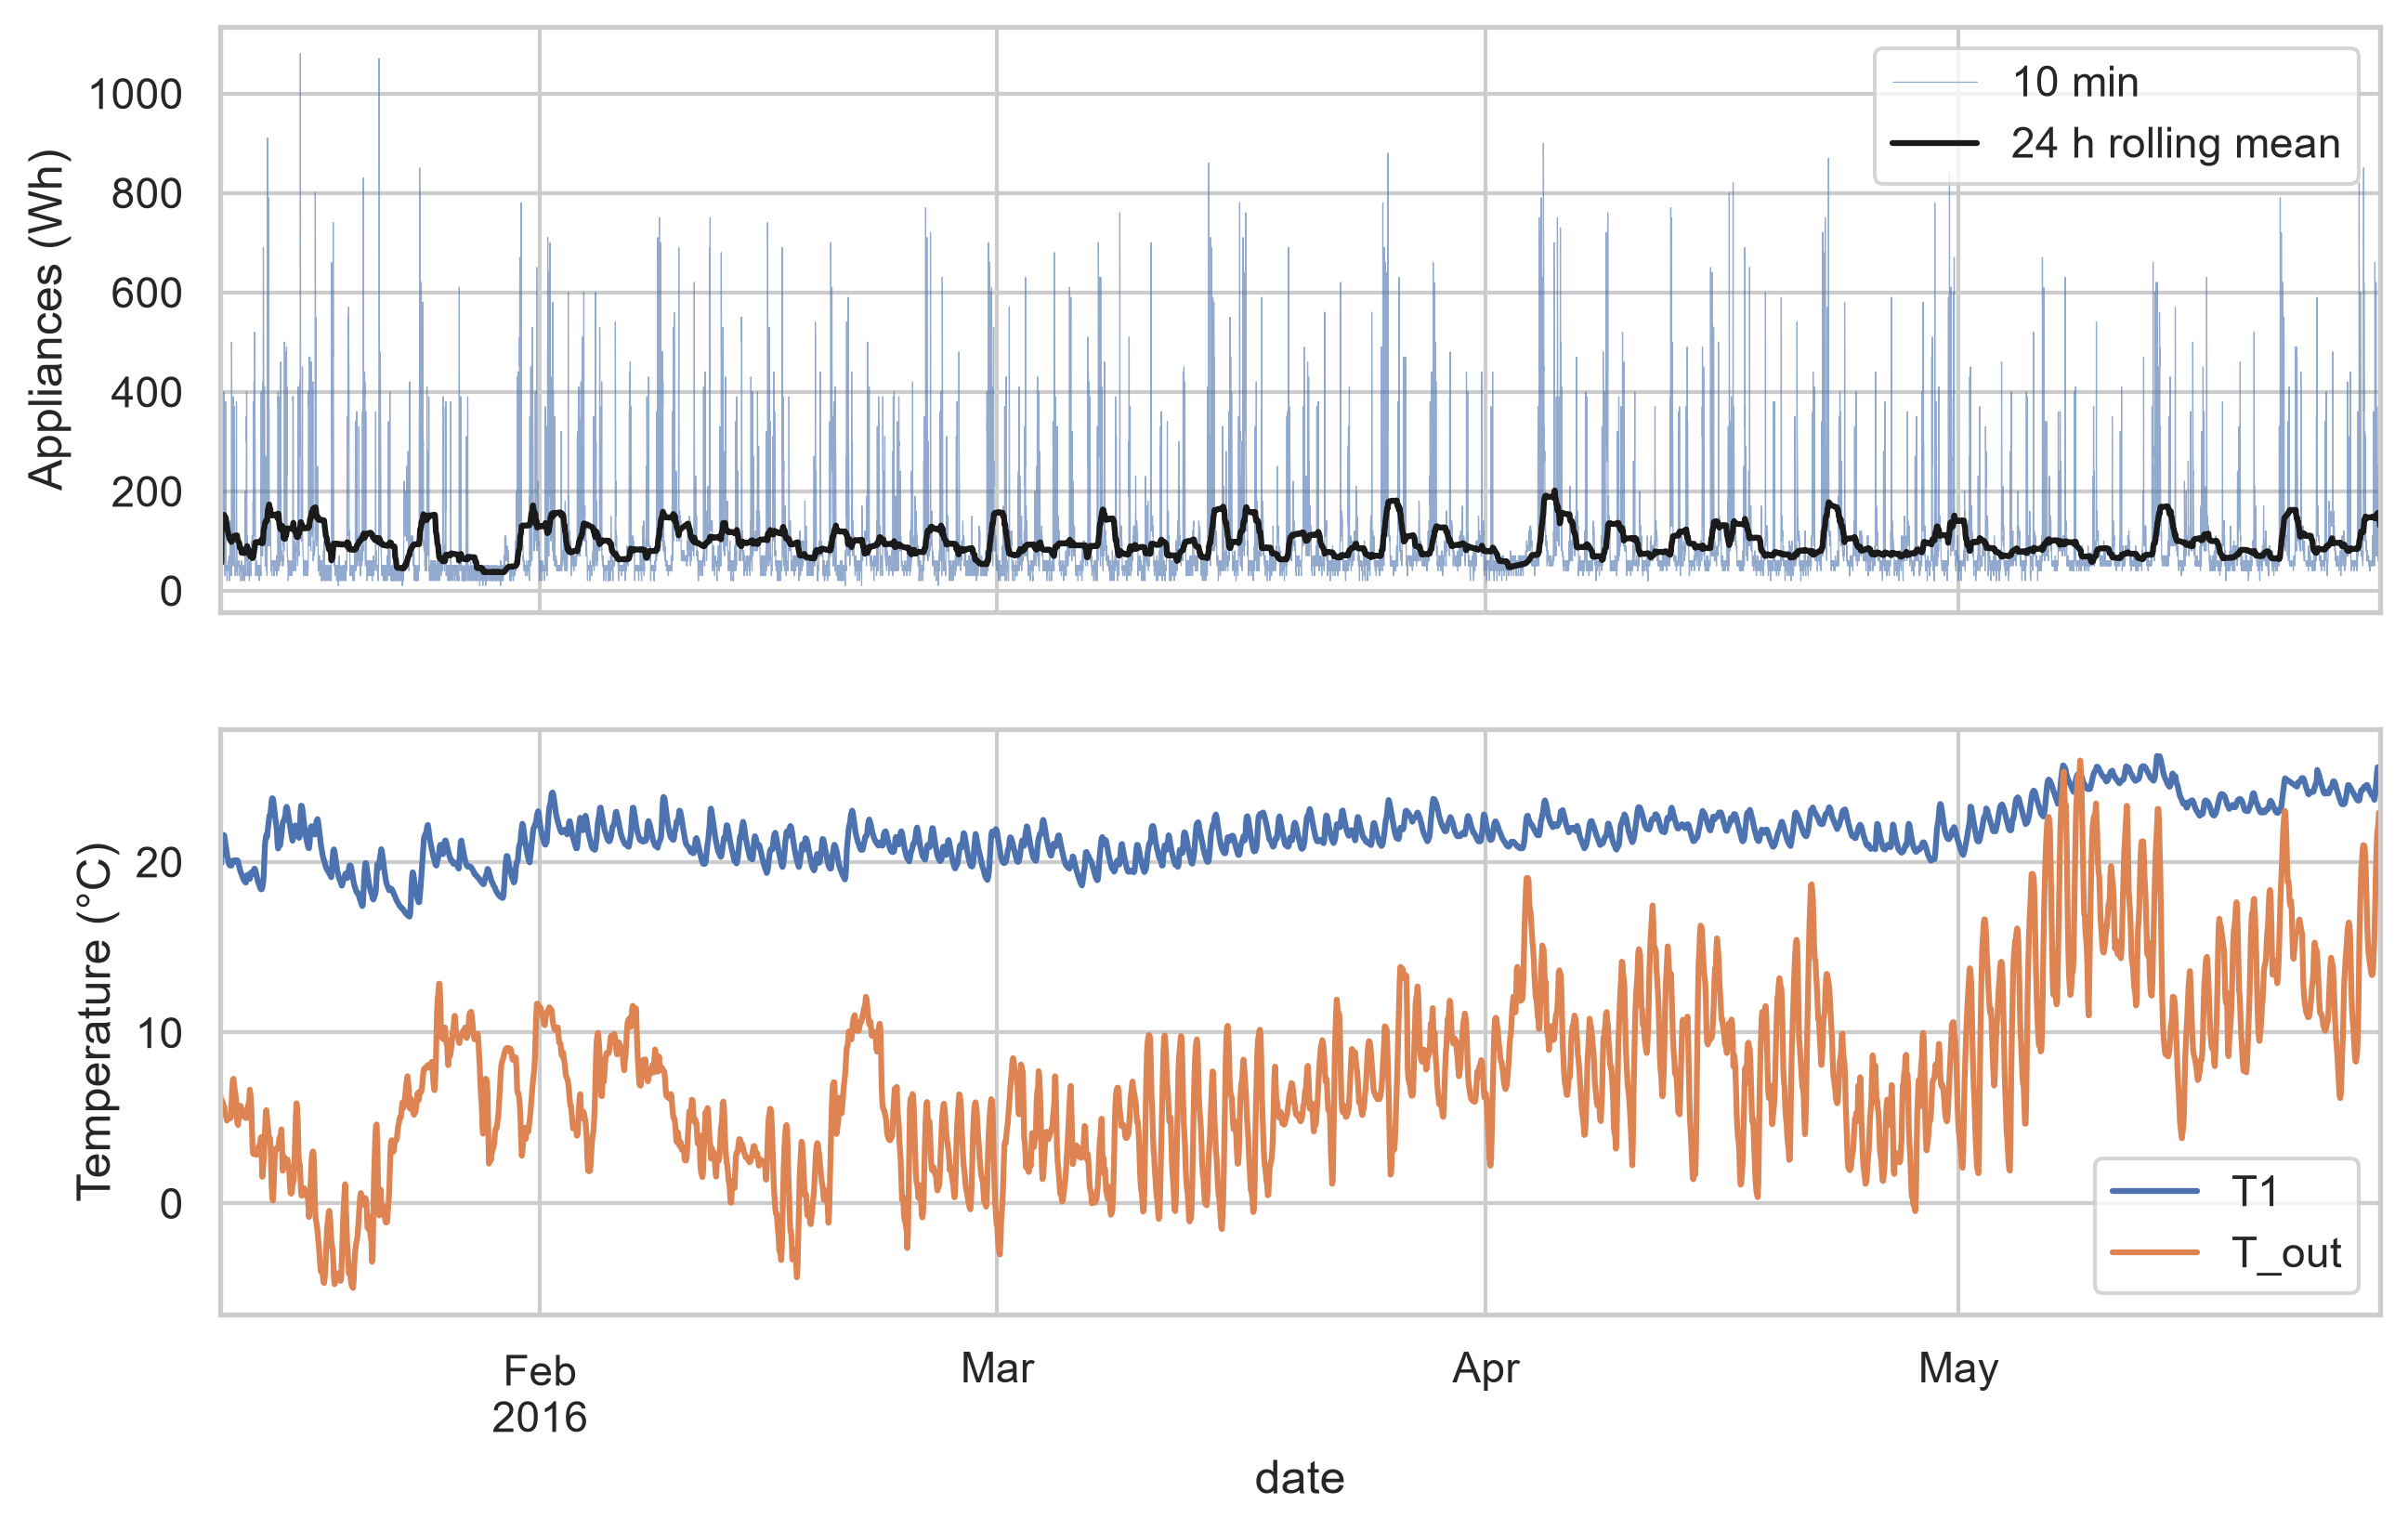

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
energy["Appliances"].plot(ax=axes[0], lw=0.3, alpha=0.6, label="10 min")
energy["Appliances"].rolling("1D").mean().plot(ax=axes[0], color="k", label="24 h rolling mean")
axes[0].set(ylabel="Appliances (Wh)"); axes[0].legend()
energy[["T1", "T_out"]].resample("h").mean().plot(ax=axes[1])
axes[1].set(ylabel="Temperature (°C)")
plt.show()

A **rolling mean** smooths short-term fluctuations and reveals the level over time. Indoor temperature `T1` is much more stable than the outdoor temperature – as expected for a well-insulated building.

### Daily and weekly patterns

Consumption depends on human behaviour, so we expect patterns over the hour of the day and the day of the week. A heatmap shows both at once:

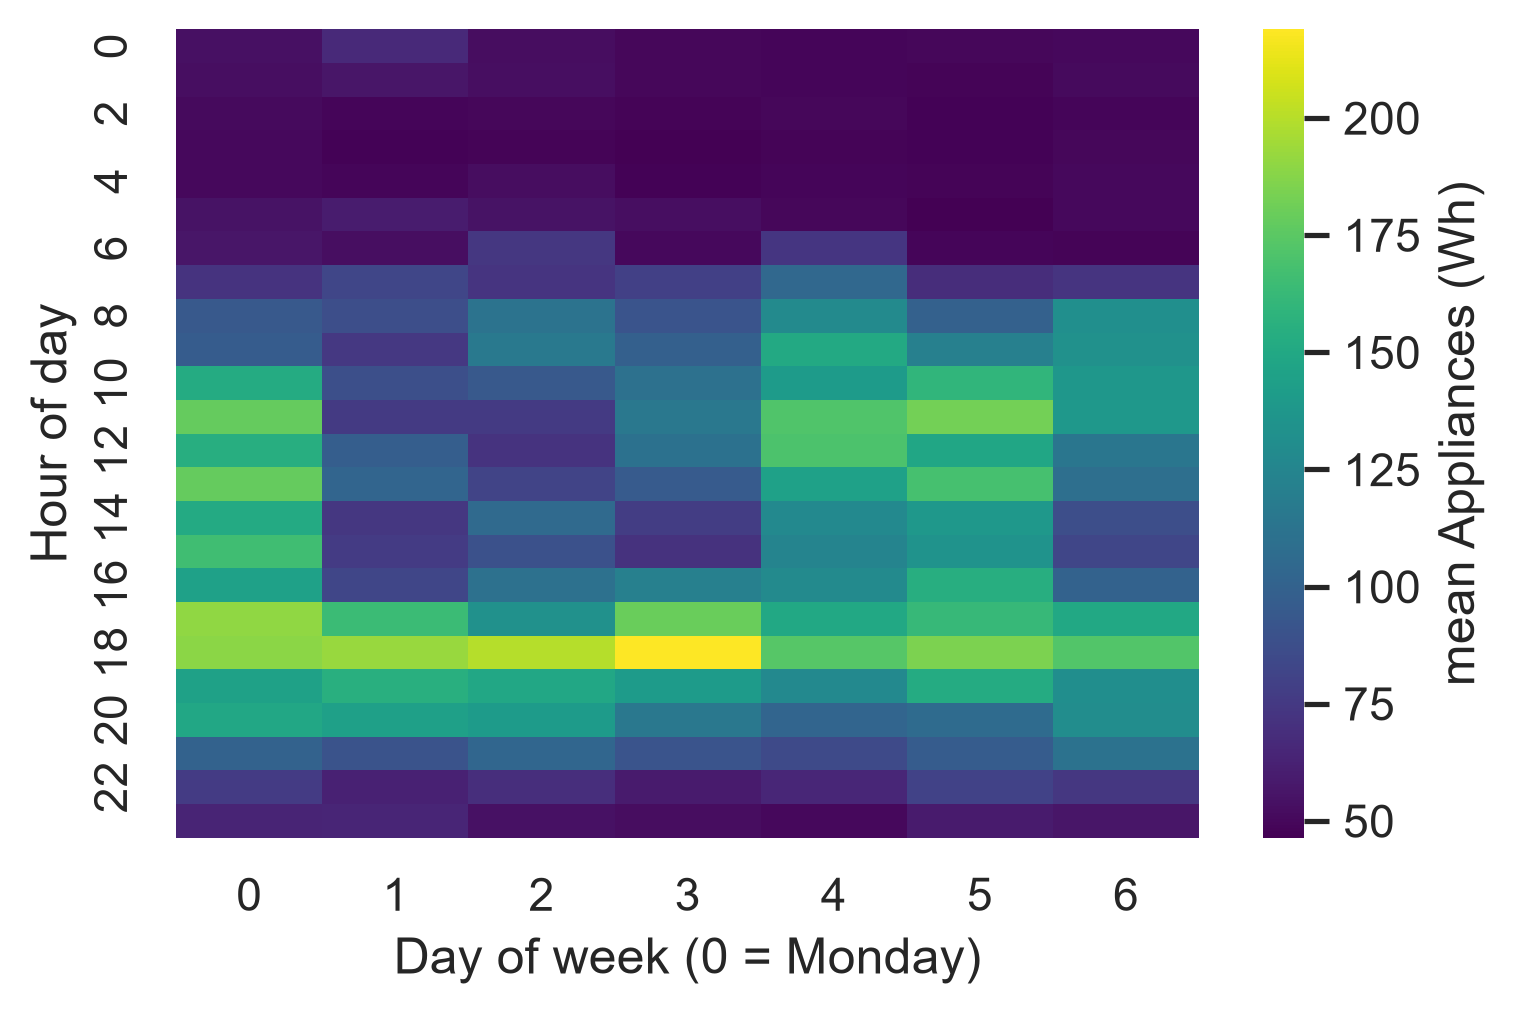

In [10]:
profile = energy.groupby([energy.index.dayofweek, energy.index.hour])["Appliances"].mean().unstack(0)
sns.heatmap(profile, cmap="viridis", cbar_kws={"label": "mean Appliances (Wh)"})
plt.xlabel("Day of week (0 = Monday)"); plt.ylabel("Hour of day")
plt.show()

**Discussion.** Low consumption at night, a rise in the morning and a peak in the evening hours – a typical residential profile. Such patterns are important for later modelling: hour of day and weekday are strong features for forecasting (Chapter 11).

### Outliers: IQR rule and robust z-score

::: {.callout-note}
## Definition: Outlier rules
- **IQR rule (Tukey):** a value is flagged if it lies below $Q_1 - 1.5\,\text{IQR}$ or above $Q_3 + 1.5\,\text{IQR}$. These are the whiskers of the box plot.
- **Robust z-score:** $z_i = \dfrac{x_i - \tilde x}{1.4826 \cdot \text{MAD}}$, flag if $|z_i| > 3.5$, where $\tilde x$ is the median. The factor 1.4826 makes MAD comparable to the standard deviation for normally distributed data.
:::

The ordinary z-score $(x_i - \bar x)/s$ is less suitable for outlier detection: the outliers themselves inflate $\bar x$ and $s$ and can hide each other (*masking*).

In [11]:
#| code-fold: false
def iqr_outliers(x, k=1.5):
    q1, q3 = x.quantile([0.25, 0.75])
    return (x < q1 - k * (q3 - q1)) | (x > q3 + k * (q3 - q1))

def robust_z(x):
    mad = (x - x.median()).abs().median()
    return (x - x.median()) / (1.4826 * mad)

for col in ["Appliances", "T1", "T_out", "RH_1"]:
    x = energy[col]
    print(f"{col:11s} IQR rule: {iqr_outliers(x).mean():6.1%}   |robust z| > 3.5: {(robust_z(x).abs() > 3.5).mean():6.1%}")

Appliances  IQR rule:  10.8%   |robust z| > 3.5:  11.2%
T1          IQR rule:   2.6%   |robust z| > 3.5:   0.2%
T_out       IQR rule:   2.2%   |robust z| > 3.5:   0.3%
RH_1        IQR rule:   0.7%   |robust z| > 3.5:   0.2%


For the room temperature and humidity, very few values are flagged; for `Appliances`, many. This confirms that a fixed rule cannot decide alone: the flags tell us where to *look*, the engineer decides what the values mean.

## Live coding: missing values in semiconductor manufacturing

SECOM contains data from a semiconductor manufacturing process: 1,567 production runs, each described by 591 sensor and process measurements, and a label pass (−1) or fail (1). The sensor names are anonymised. Many signals have gaps. A small obstacle on the way: in the repository's metadata the label is not marked as the target variable – another example of incomplete metadata. The helper function below therefore identifies the label column from its values.

Label column: 'class', measurement columns: 590, ignored non-numeric columns: ['timestamp']
Runs: 1567, failed runs: 104
Features: 590, with any missing value: 538, more than 50 % missing: 28


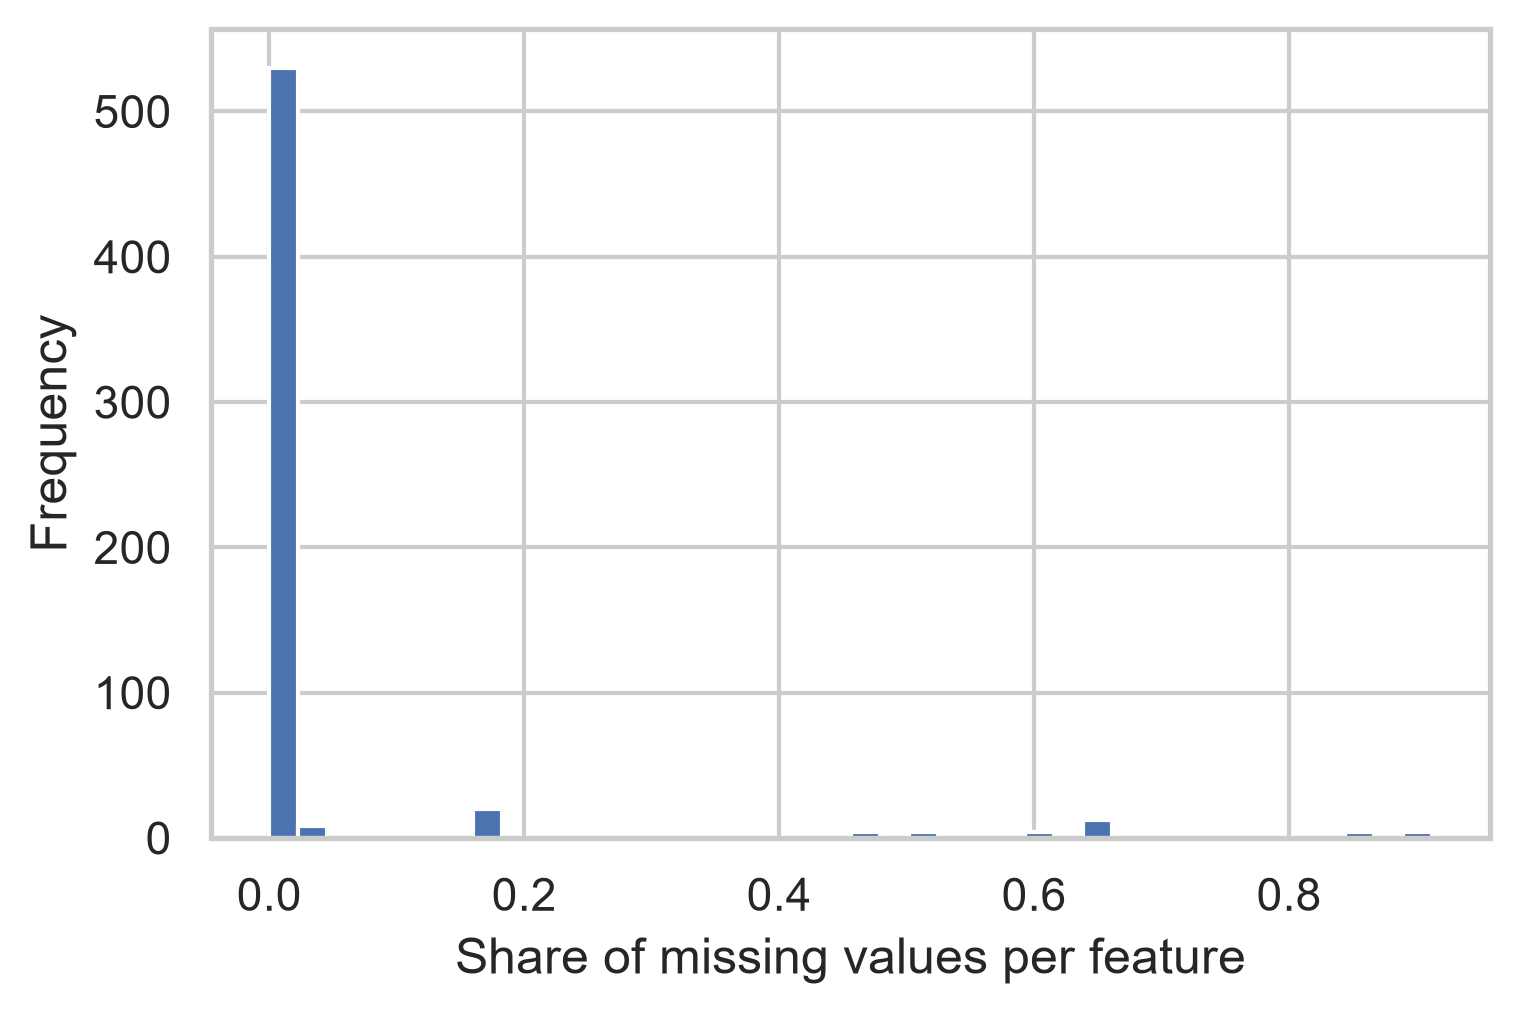

In [12]:
#| code-fold: false
def load_secom():
    """SECOM: return the process measurements X and the label y (-1 = pass, 1 = fail).

    In the UCI repository the label is not marked as target variable, so we find it
    ourselves: the only numeric column whose values are exactly -1 and 1.
    """
    df = fetch_ucirepo(id=179).data.original
    num = df.select_dtypes("number")
    labels = [c for c in num.columns if set(num[c].dropna().unique()) == {-1, 1}]
    if len(labels) != 1:
        labels = [c for c in df.columns if any(k in str(c).lower() for k in ("pass", "fail", "label"))]
    assert len(labels) == 1, f"Label column not found unambiguously: {labels}"
    y = df[labels[0]].astype(int)
    X = num.drop(columns=labels, errors="ignore")
    print(f"Label column: {labels[0]!r}, measurement columns: {X.shape[1]}, "
          f"ignored non-numeric columns: {[c for c in df.columns if c not in num.columns]}")
    return X, y

X, y = load_secom()
missing = X.isna().mean().sort_values(ascending=False)
print(f"Runs: {len(X)}, failed runs: {(y == 1).sum()}")
print(f"Features: {X.shape[1]}, with any missing value: {(missing > 0).sum()}, "
      f"more than 50 % missing: {(missing > 0.5).sum()}")
missing.plot.hist(bins=40, xlabel="Share of missing values per feature")
plt.show()

In [13]:
# Is the missingness itself related to the outcome?
miss_rate = X.isna().mean(axis=1)
print(miss_rate.groupby(y).describe().round(3))

# Constant features carry no information
n_constant = (X.nunique(dropna=True) <= 1).sum()
print("Constant features:", n_constant)

        count   mean    std    min    25%    50%    75%    max
class                                                         
-1     1463.0  0.046  0.023  0.007  0.034  0.041  0.054  0.258
 1      104.0  0.043  0.017  0.014  0.034  0.041  0.047  0.108
Constant features: 116


**Discussion.** Most features are complete or nearly complete, but a group of features has a large share of missing values – often entire sensors that were only recorded for part of the runs. In addition, a considerable number of features are constant and can be removed without loss. Comparing the share of missing values between passed and failed runs is a quick check of whether missingness could be informative (MAR/MNAR rather than MCAR).

A pragmatic preparation for SECOM, which we will use in Chapter 9:

1. remove constant features,
2. remove features with more than 50 % missing values,
3. impute the remaining gaps with the median,
4. standardise all features.

::: {.callout-warning}
## Pitfall: preprocessing before splitting
Medians for imputation and means/standard deviations for scaling must be computed on the **training data only** and then applied to the test data. Computing them on the full dataset leaks information from the test set into the model. In scikit-learn, putting all steps into a `Pipeline` prevents this automatically (Chapter 6).

*And how are gaps in the test data filled?* With the **training** median as well – not with a median computed from the test data. The median is a parameter of the model, just like a regression coefficient: it is estimated once from the training data and then applied unchanged to all new data. Three reasons:

- In operation there is no "test median": new data often arrive one observation at a time – a single production run, a single sensor reading – and a median cannot be computed from one value.
- The model must always receive the same preprocessing. If a gap was filled with 52.3 during training but with 48.9 during testing, the model sees inputs it was not trained on.
- A test median would itself be a small leak: the prediction for one test point would depend on the other test points.

The same holds for scaling, PCA and every other preprocessing step: `fit` on the training data, `transform` on training *and* test data. If the distribution of new data drifts away from the training data, the remedy is to monitor the drift and retrain – not to compute statistics on the test data. (One legitimate exception: if a whole batch – say all wafers of a lot – is always available at prediction time, statistics per batch may be used, but then in exactly the same way during training.)
:::

## Back to the decision

For a go/no-go recommendation, three questions matter: Are enough features usable? Are there enough examples of the event we want to predict? And are the gaps understood? We use simple, transparent criteria: at least half of the features should be non-constant with at most 50 % missing values, and there should be at least 50 failed runs to learn from.

In [14]:
#| code-fold: false
usable = (X.nunique(dropna=True) > 1) & (X.isna().mean() <= 0.5)
n_fail = int((y == 1).sum())
print(f"Usable features: {usable.sum()} of {X.shape[1]} ({usable.mean():.0%})")
print(f"Failed runs: {n_fail} of {len(y)} ({n_fail / len(y):.1%})")
if usable.mean() >= 0.5 and n_fail >= 50:
    print("Decision: GO – with a data-quality work package in the first project phase.")
else:
    print("Decision: NO-GO for now – improve data acquisition first.")

Usable features: 446 of 590 (76%)
Failed runs: 104 of 1567 (6.6%)
Decision: GO – with a data-quality work package in the first project phase.


Whatever the code prints, the recommendation should name the conditions: the sensor names are anonymised, so no process engineer can yet judge which signals are physically relevant; the missing values must be explained (are they MAR or MNAR?); and roughly one hundred failures is a small number for a problem with hundreds of candidate features. Chapter 9 will show how hard the prediction actually is.

::: {.callout-important}
## Key takeaways
- Describe distributions by location, spread and shape; compare classical (mean, s) and robust (median, IQR, MAD) statistics.
- Read raw files deliberately: separator, missing value code, time format, units and time zone are documented in the metadata.
- Check data quality systematically: missing values, gaps in time, implausible values, frozen sensors, outliers.
- Outlier rules flag candidates – domain knowledge decides whether they are errors or important events.
- The treatment of missing data depends on the mechanism (MCAR, MAR, MNAR).
:::

## Exercises

<div class="exercises">

1. Compare the IQR rule and the robust z-score for `Appliances` after a log transformation, `np.log(energy["Appliances"])`. How many values are flagged now? What does this tell you about the "outliers" in the original scale?
2. Check all temperature columns (`T1`–`T9`, `T_out`) and humidity columns (`RH_1`–`RH_9`, `RH_out`) of the energy dataset for physically implausible values and for "frozen" periods, i.e. more than 6 identical consecutive values.
3. Resample the energy data to hourly values. Which aggregation (mean, sum, max, last) is correct for `Appliances`, which for the temperatures? Explain.
4. Show that the random variables `rv1` and `rv2` carry no information about `Appliances`. Compare their correlation with that of the outdoor temperature.
5. For SECOM: propose a strategy for features with 0–5 %, 5–50 % and more than 50 % missing values, and implement steps 1–3 of the preparation described above. How many features remain?
6. Change the DWD code to load a weather station near your home town. The station list `TU_Stundenwerte_Beschreibung_Stationen.txt` is in the same DWD folder.
7. Compute the mean temperature per hour of the day for the DWD data and plot the daily cycle. At which hour is it warmest – and does the result change if you convert the time stamps from UTC to German local time?
8. Determine type and role (see Chapter 1) of each column of the raw DWD file (`STATIONS_ID`, `MESS_DATUM`, `QN_9`, `TT_TU`, `RF_TU`, `eor`) for the question "How does the air temperature in Trier vary over the day?".

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [15]:
#| code-fold: false
log_app = np.log(energy["Appliances"])
print(f"IQR rule:          {iqr_outliers(log_app).mean():.1%}")
print(f"|robust z| > 3.5:  {(robust_z(log_app).abs() > 3.5).mean():.1%}")

IQR rule:          6.5%
|robust z| > 3.5:  7.4%


After the log transformation far fewer values are flagged. Many "outliers" on the original scale were simply the long right tail of a skewed distribution. Outlier rules implicitly assume a roughly symmetric distribution – applying them to skewed data without transformation flags normal behaviour.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [16]:
#| code-fold: false
temp_cols = [f"T{i}" for i in range(1, 10)] + ["T_out"]
rh_cols = [f"RH_{i}" for i in range(1, 10)] + ["RH_out"]
print("Temperature range (°C):", energy[temp_cols].min().min(), "to", energy[temp_cols].max().max())
print("Humidity outside 0–100 %:", ((energy[rh_cols] < 0) | (energy[rh_cols] > 100)).sum().sum())

def longest_constant_run(x):
    runs = (x != x.shift()).cumsum()
    return x.groupby(runs).size().max()

frozen = {c: longest_constant_run(energy[c]) for c in temp_cols + rh_cols}
pd.Series(frozen).sort_values(ascending=False).head()

Temperature range (°C): -6.065 to 29.85666667
Humidity outside 0–100 %: 0


RH_6    353
T9       79
T7       78
T5       62
RH_8     42
dtype: int64

The temperature and humidity ranges should be physically plausible. Runs of identical values occur in practice because sensors report with limited resolution and indoor conditions change slowly; a run is suspicious only if it is long compared with the normal dynamics (e.g. several hours for an outdoor temperature). Here, the outdoor weather comes from an airport station with lower update rate and was interpolated to 10 minutes – this explains smooth or repeated values in the `_out` columns.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [17]:
#| code-fold: false
hourly = energy.resample("h").agg({"Appliances": "sum", "lights": "sum",
                                   "T1": "mean", "T_out": "mean"})
hourly.head()

,Appliances,lights,T1,T_out
date,,,,
2016-01-11 17:00:00,330,210,19.890000,6.308333
2016-01-11 18:00:00,1060,310,19.897778,5.941667
2016-01-11 19:00:00,1040,150,20.495556,6.000000
2016-01-11 20:00:00,750,210,20.961111,6.000000
2016-01-11 21:00:00,620,140,21.311667,5.833333


`Appliances` is an energy per interval (Wh in 10 minutes). The energy of one hour is the **sum** of the six 10-minute values (unit: Wh per hour, i.e. the mean power in W). Temperatures are state variables: the hourly value is the **mean** (or, for an instantaneous value, the last one). Summing temperatures would be physically meaningless. `max` is useful for questions about peaks, e.g. dimensioning a fuse.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [18]:
#| code-fold: false
energy[["rv1", "rv2", "T_out", "T2", "RH_out"]].corrwith(energy["Appliances"]).round(3)

rv1      -0.011
rv2      -0.011
T_out     0.099
T2        0.120
RH_out   -0.152
dtype: float64

The correlations of `rv1` and `rv2` with `Appliances` are close to zero. (Check also with `energy["rv1"].equals(energy["rv2"])` whether the two random columns are identical copies – a nice example of a redundant feature.) The weather variables show small but non-zero correlations. Note that with almost 20,000 observations even tiny correlations can be "statistically significant" (Chapter 4) – the size of the correlation matters more than its p-value.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

In [19]:
#| code-fold: false
X1 = X.loc[:, X.nunique(dropna=True) > 1]              # 1. drop constant features
X2 = X1.loc[:, X1.isna().mean() <= 0.5]                # 2. drop > 50 % missing
X3 = X2.fillna(X2.median())                            # 3. median imputation
print(f"{X.shape[1]} -> {X1.shape[1]} (constant removed) -> {X2.shape[1]} (sparse removed)")
print("Remaining missing values:", X3.isna().sum().sum())

590 -> 474 (constant removed) -> 446 (sparse removed)
Remaining missing values: 0


Strategy: 0–5 % missing → median imputation (little influence on results); 5–50 % → median or model-based imputation plus an indicator variable "was missing"; more than 50 % → remove the feature, unless domain experts know that it is important (then investigate why it is missing). In a real project the imputation would be fitted on the training data only (see the warning above).
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6
Open the station list in a browser or read it with pandas, find your station and replace `05100` in the file name. The file name of the `recent` product always has the form `stundenwerte_TU_<ID>_akt.zip`, where `<ID>` is the five-digit station ID with leading zeros. Not all stations measure all variables – if the file does not exist, choose a neighbouring station.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 7

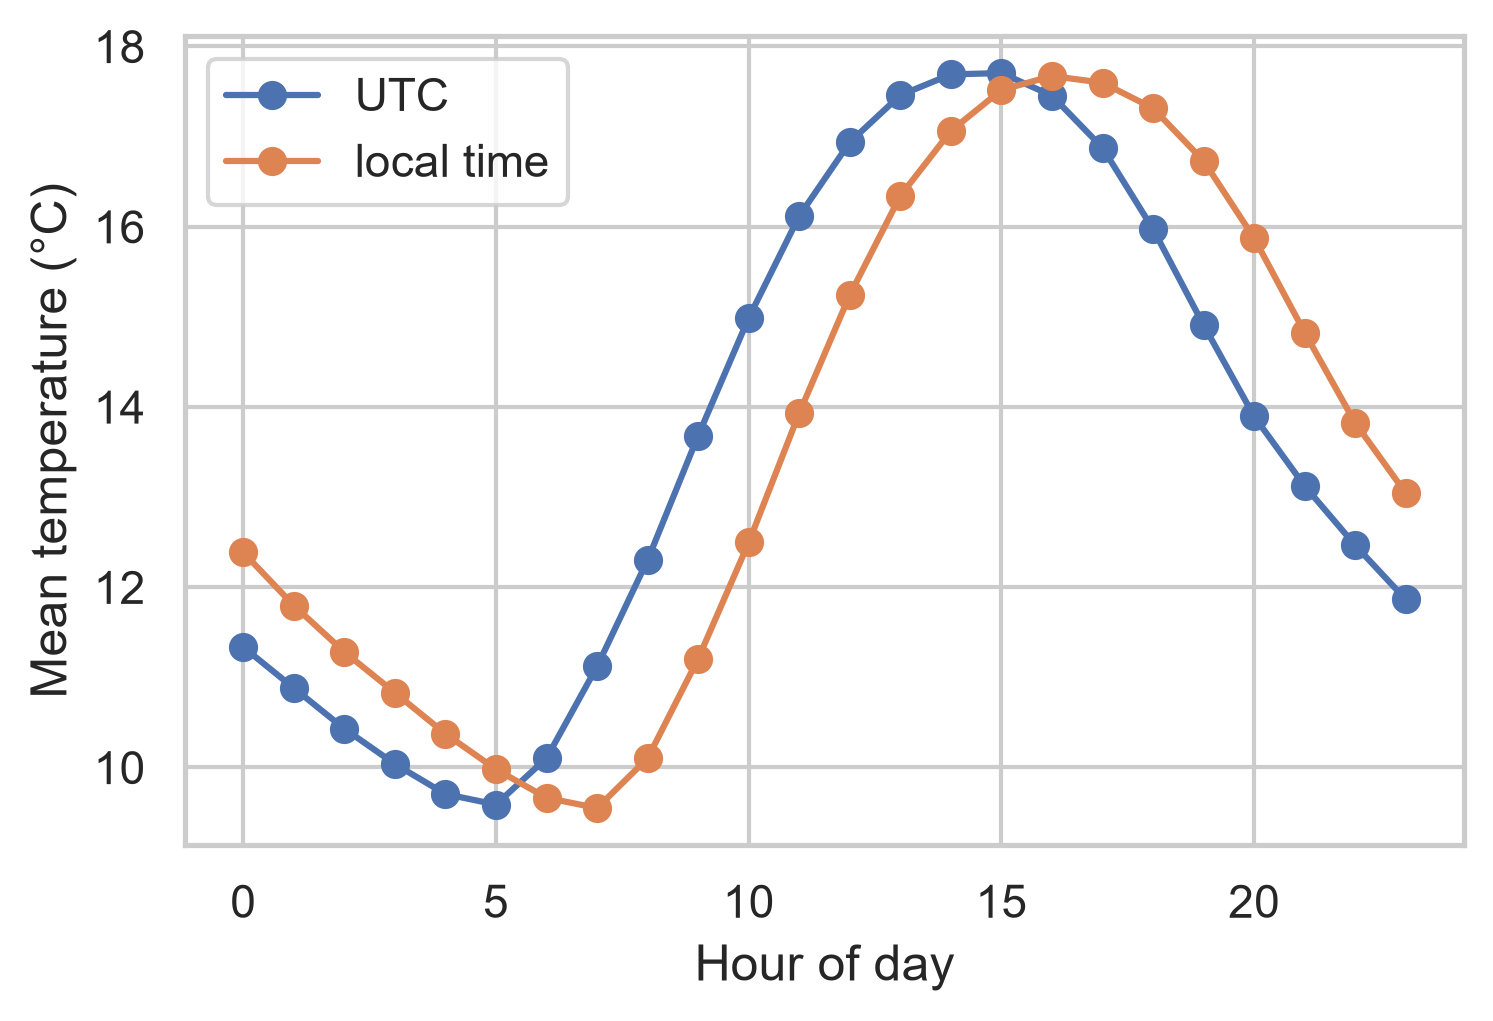

UTC           15
local time    16
dtype: int32

In [20]:
#| code-fold: false
# The DWD time stamps are in UTC: declare this (tz_localize), then convert to German time.
local = weather.tz_localize("UTC").tz_convert("Europe/Berlin")
cycle = pd.DataFrame({                                    # mean temperature per hour of day
    "UTC": weather.groupby(weather.index.hour)["temp_C"].mean(),
    "local time": local.groupby(local.index.hour)["temp_C"].mean(),
})
ax = cycle.plot(marker="o")
ax.set(xlabel="Hour of day", ylabel="Mean temperature (°C)")
plt.show()
cycle.idxmax()                                            # hour of the maximum

The maximum typically occurs in the early or mid afternoon. In local time the curve is shifted by one hour in winter and two hours in summer, so the hour of the maximum changes accordingly. This is exactly the kind of shift that causes errors when weather data are merged with production data recorded in local time.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 8
- `STATIONS_ID`: categorical (nominal) – a code, although stored as a number; constant within the file.
- `MESS_DATUM`: time stamp – numeric (differences are durations); after conversion, the index of the time series.
- `QN_9`: categorical – a code for the quality level of the record. Whether the levels are ordered must be looked up in the DWD documentation; computing a mean is meaningless either way.
- `TT_TU`: continuous (°C) – the variable of interest for this question; there is no target, because nothing is predicted.
- `RF_TU`: continuous (%) – not needed for this question.
- `eor`: not a variable at all – a marker for "end of record" in each line of the file.
:::